[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Reproducibilidad de un EDA.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo IV: *Del análisis al informe*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se revisarán las buenas prácticas de reproducibilidad y se aplicarán a `mpg`: preguntas de análisis, auditoría inicial y comparación de grupos.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* **Ejercicio básico:** lo que todos deben dominar.
* **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencias.

Este *notebook* integra lo visto en los *notebooks* `01` a `23`. Para la API: [py311 · 20 Limpieza y datos faltantes](https://github.com/PythonistaMX/py311/blob/main/20_limpieza_y_datos_faltantes.ipynb), [py311 · 24 Métodos `groupby()`](https://github.com/PythonistaMX/py311/blob/main/24_metodos_groupby.ipynb), [py311 · 31 Introducción a *Seaborn*](https://github.com/PythonistaMX/py311/blob/main/31_introduccion_a_seaborn.ipynb) y la documentación de [*SciPy* · `scipy.stats`](https://docs.scipy.org/doc/scipy/reference/stats.html).

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3; si algo se ve distinto, se sigue lo que muestra este *notebook*.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

### Objetos de los *notebooks* anteriores.

Este *notebook* es independiente: la siguiente celda vuelve a crear lo que se necesita de los *notebooks* anteriores.

* La siguiente celda definirá las funciones reutilizables `perfil_rapido` y `resumen_por_grupo` y recreará `autos_limpio` con las decisiones de `23_eda_completo_con_mpg.ipynb`: `origin` como categoría, `litros_100km` y cuartiles de peso.

In [2]:
def perfil_rapido(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_faltantes": df.isna().sum(),
        "pct_faltantes": (df.isna().mean() * 100).round(1),
        "n_unicos": df.nunique(dropna=True),
        "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })


def resumen_por_grupo(df, columna, grupo):
    return df.groupby(grupo, observed=True)[columna].agg(
        n="count", media="mean", mediana="median", desv_est="std",
        iqr=lambda s: s.quantile(0.75) - s.quantile(0.25),
    ).round(2)


autos = pd.read_csv(os.path.join(DATA, "mpg.csv"))
autos_limpio = (
    autos.astype({"origin": pd.CategoricalDtype(["usa", "europe", "japan"])})
    .assign(litros_100km=lambda d: 235.215 / d["mpg"])
    .assign(cuartil_peso=lambda d: pd.qcut(d["weight"], 4, labels=["Q1 ligero", "Q2", "Q3", "Q4 pesado"]))
)
autos_limpio.shape

(398, 11)

---
## 1. Buenas prácticas de reproducibilidad (15 min).

| Práctica | Cómo | Por qué |
|---|---|---|
| **Restart & Run All** antes de compartir | Menú *Kernel* → *Restart Kernel and Run All Cells* (en *VS Code* y *Codespaces* el botón puede llamarse *Reiniciar* y *Ejecutar todo*) | Un *notebook* que solo corre en cierto orden no es reproducible |
| Orden fijo | Preparación → datos → calidad → descripción → relaciones → inferencia → informe | Quien lo lea sigue el razonamiento |
| Semilla | `rng = np.random.default_rng(401)` en la preparación y `random_state=401` en `bootstrap`/`permutation_test` | Mismos números si se ejecuta todo de principio a fin: con un solo generador compartido, el resultado de una celda depende de cuántas veces se ejecutó antes; con `random_state=401` en la celda, se repite siempre |
| Rutas relativas | `os.path.join(DATA, "archivo.csv")` | Funciona en *Codespaces*, en tu máquina y en la de otra persona |
| Datos crudos intactos | Leer el original y guardar el limpio con otro nombre (`*_limpio.csv`) | Siempre se puede rehacer la limpieza |
| Funciones reutilizables | `perfil_rapido`, `resumen_por_grupo`, `d_cohen`… | Menos errores de copiar y pegar |
| Dependencias | Si usas una biblioteca nueva, agrégala a `requirements.txt`; anota también las versiones que usaste | El *Codespace* de otra persona la instalará al crearse, pero `requirements.txt` fija versiones **mínimas**: con versiones más nuevas los resultados pueden cambiar un poco |
| Decisiones escritas | Una celda de Markdown por decisión: qué, por qué y cuántas filas afecta | Quien lea el análisis puede entender y revisar cada decisión |

**Nota:** en *Codespaces*, `requirements.txt` se instala solo al crear el entorno. Si lo modificas con el *Codespace* abierto, ejecuta `pip install -r requirements.txt` en la terminal.

> 💡 **La semilla, en palabras.** Una semilla hace que los números «al azar» salgan siempre iguales, como barajar un mazo con una receta fija: el resultado parece aleatorio, pero cualquiera que use las mismas herramientas puede repetirlo. Sin semilla, tu intervalo de confianza de mañana no coincide con el de hoy.

> 💡 **Reproducir no es replicar.** **Reproducir** es obtener los mismos números con los mismos datos y el mismo código; **replicar** es obtenerlos con datos nuevos. Aquí se pide lo primero.

**¿Por qué importa?** Ejecutar el análisis de nuevo en otro *Codespace* permite comprobar que los números salen de esos datos y de esos pasos (eso no prueba que el análisis sea correcto, pero sí que se puede revisar). Si no corre de principio a fin con los mismos números, nadie puede comprobar los hallazgos y el análisis pierde credibilidad. Las prácticas de la tabla son baratas si se aplican desde el inicio y muy costosas si se intentan al final.

---
## 2. Taller: reproducibilidad aplicada a `mpg` (35 min).

Los siguientes ejercicios aplican las buenas prácticas de la sección 1 y las funciones reutilizables al *dataset* `mpg` que se recorrió en `23_eda_completo_con_mpg.ipynb`.

**Estructura del informe.** El informe de hallazgos que se trabajará en `25_estructura_del_informe_y_comunicacion.ipynb` y `26_del_notebook_al_informe.ipynb` tiene esta estructura: **resumen ejecutivo** (máximo 150 palabras), **datos y método**, **hallazgos** (uno por pregunta, con su gráfica, su número clave, su incertidumbre y su tamaño del efecto), **limitaciones** y **reproducibilidad**. La sección 2.6 de `23_eda_completo_con_mpg.ipynb` es un ejemplo breve de ese formato.

### Ejercicio 1 · Preguntas de análisis.

**🎯 Objetivo:** formular las preguntas con las que arranca cualquier EDA. **Qué se espera aprender:** a escribir preguntas **respondibles** con las columnas disponibles, que guíen el resto del análisis y anticipen confusores.

Escribe 2 o 3 preguntas de análisis para `mpg` que no se hayan respondido en `23_eda_completo_con_mpg.ipynb` (por ejemplo, con `acceleration`, `displacement` o `horsepower`). Cada una debe poder responderse con las columnas disponibles, nombrar las variables involucradas y anticipar al menos un confusor o sesgo posible.

**✅ Respuesta sugerida:**

Ejemplo:
1. ¿Se relaciona la aceleración (`acceleration`) con la potencia (`horsepower`)? Confusor anticipado: el peso (los autos más pesados necesitan más potencia).
2. ¿Difiere la potencia según el origen (`origin`)? Confusor anticipado: el número de cilindros y el tamaño del motor.
3. ¿Cambió el peso de los modelos entre 1970 y 1982? Sesgo posible: `mpg` no incluye todos los modelos del mercado, solo los de la muestra.

### Ejercicio 2 · Auditoría inicial.

**🎯 Objetivo:** aplicar las funciones reutilizables a los datos crudos de `mpg`. **Qué se espera aprender:** a convertir los resultados de la auditoría en decisiones escritas, con su justificación y el número de filas afectadas.

Con `autos` (los datos crudos de `mpg`), aplica `perfil_rapido`, el conteo de duplicados (exactos y por la llave que corresponda) y `describe()`. Escribe en Markdown las decisiones de calidad que tomarías.

* La siguiente celda muestra una solución posible.

In [3]:
(perfil_rapido(autos),
 {"duplicados exactos": int(autos.duplicated().sum()),
  "nombre + año repetidos": int(autos.duplicated(subset=["name", "model_year"]).sum())},  # llave de mpg
 autos.describe().T.round(1))

(                dtype  n_faltantes  pct_faltantes  n_unicos  \
 mpg           float64            0            0.0       129   
 cylinders       int64            0            0.0         5   
 displacement  float64            0            0.0        82   
 horsepower    float64            6            1.5        93   
 weight          int64            0            0.0       351   
 acceleration  float64            0            0.0        95   
 model_year      int64            0            0.0        13   
 origin            str            0            0.0         3   
 name              str            0            0.0       305   
 
                                 ejemplo  
 mpg                                18.0  
 cylinders                             8  
 displacement                      307.0  
 horsepower                        130.0  
 weight                             3504  
 acceleration                       12.0  
 model_year                           70  
 origin       

**✅ Respuesta sugerida:**

Con `mpg` como ejemplo: no hay duplicados exactos; nombre + año no es una llave: los 2 pares repetidos (*ford pinto* de 1975 y *plymouth reliant* de 1981) difieren en motor, peso o consumo, así que no son copias (lo más probable es que sean versiones distintas del mismo modelo) y se conservan; además, 93 nombres se repiten (como se vio en `23_eda_completo_con_mpg.ipynb`), por lo que un mismo nombre no basta para hablar de duplicado; `horsepower` tiene 6 faltantes (1.5%) que se excluyen solo donde se usa esa variable; 3 y 5 cilindros se excluyen de comparaciones por cilindros por tener menos de 5 modelos; `origin` pasa a `category`.

### Ejercicio 3 · Consumo por número de cilindros.

**🎯 Objetivo:** repetir el flujo de comparación de grupos con otra variable. **Qué se espera aprender:** a cuestionar si una diferencia significativa y grande es un hallazgo **independiente** de otras variables correlacionadas.

En `autos_limpio`, compara `litros_100km` entre autos de 4, 6 y 8 cilindros (excluye 3 y 5): resumen por grupo, ANOVA de Welch, η² y un diagrama de caja. ¿Tiene sentido esta comparación como hallazgo independiente del peso?

* La siguiente celda muestra una solución posible.

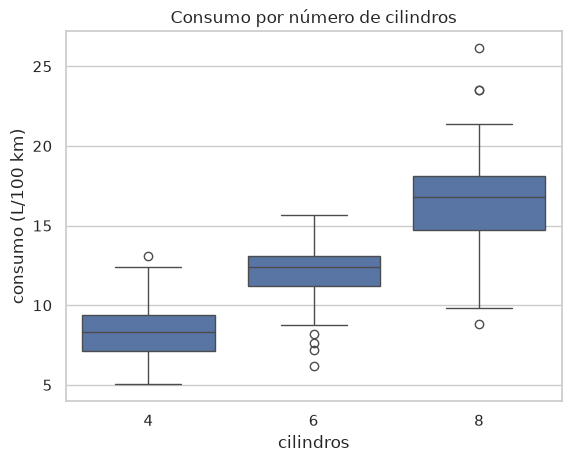

(             n  media  mediana  desv_est   iqr
 cylinders                                     
 4          204   8.33     8.33      1.60  2.28
 6           84  12.11    12.38      1.87  1.87
 8          103  16.24    16.80      2.88  3.39,
 6.305425574622281e-65,
 0.725)

In [4]:
cilindros_comunes = autos_limpio[autos_limpio["cylinders"].isin([4, 6, 8])]
grupos_cil = [g["litros_100km"].to_numpy() for _, g in cilindros_comunes.groupby("cylinders")]
media_cil = cilindros_comunes["litros_100km"].mean()
por_cil = cilindros_comunes.groupby("cylinders")["litros_100km"].agg(["count", "mean"])
eta2_cil = (por_cil["count"] * (por_cil["mean"] - media_cil) ** 2).sum() / ((cilindros_comunes["litros_100km"] - media_cil) ** 2).sum()
ax = sns.boxplot(cilindros_comunes, x="cylinders", y="litros_100km")
ax.set(xlabel="cilindros", ylabel="consumo (L/100 km)", title="Consumo por número de cilindros")
plt.show()
(resumen_por_grupo(cilindros_comunes, "litros_100km", "cylinders"),
 float(anova_oneway(cilindros_comunes["litros_100km"], cilindros_comunes["cylinders"], use_var="unequal").pvalue),
 round(float(eta2_cil), 3))

**✅ Respuesta sugerida:**

El consumo medio sube con los cilindros: 8.3 L/100 km con 4, 12.1 con 6 y 16.2 con 8 (ANOVA de Welch *p* < 0.001; η² = 0.73). Pero **no** es un hallazgo independiente del peso: cilindros, peso, desplazamiento y potencia tienen correlaciones de 0.84 a 0.95 entre sí. Los autos de 8 cilindros son, además, los más pesados; separar el efecto de cada característica requeriría comparar a igual peso (o un modelo de regresión, fuera del alcance del curso).

### Reto 1 · ¿Los autos se volvieron más eficientes con los años?

**🎯 Objetivo:** analizar una tendencia temporal con un posible confusor. **Qué se espera aprender:** a separar, de forma descriptiva, la parte de un cambio que se explica por otra variable.

Grafica la mediana del consumo y del peso por `model_year`. ¿Cuánto bajó el consumo de 1970 a 1982? ¿Qué parte de esa mejora podría deberse a que los autos se hicieron más ligeros? (pista: compara el consumo por año dentro de un mismo cuartil de peso).

* La siguiente celda grafica la mediana del consumo y del peso por año, y calcula la mediana del consumo en dos periodos dentro de cada cuartil de peso.

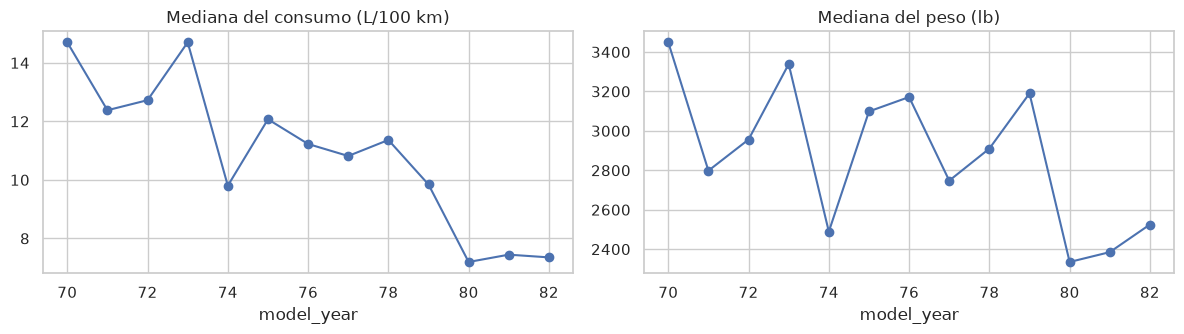

(            litros_100km  weight
 model_year                      
 70                  14.7  3449.0
 76                  11.2  3171.5
 82                   7.4  2525.0,
                        litros_100km        weight        
                               count median  count  median
 cuartil_peso periodo                                     
 Q1 ligero    1970-1975           33   8.40     33  2065.0
              1976-1982           67   6.88     67  2035.0
 Q2           1970-1975           42  10.23     42  2419.0
              1976-1982           57   8.40     57  2572.0
 Q3           1970-1975           40  13.07     40  3148.5
              1976-1982           59  11.42     59  3193.0
 Q4 pesado    1970-1975           67  16.80     67  4294.0
              1976-1982           33  14.26     33  3955.0)

In [5]:
por_anio = autos_limpio.groupby("model_year")[["litros_100km", "weight"]].median()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
por_anio["litros_100km"].plot(ax=axes[0], marker="o", title="Mediana del consumo (L/100 km)")
por_anio["weight"].plot(ax=axes[1], marker="o", title="Mediana del peso (lb)")
plt.tight_layout()
plt.show()
dentro_cuartiles = (autos_limpio
                    .assign(periodo=lambda d: np.where(d["model_year"] <= 75, "1970-1975", "1976-1982"))
                    .groupby(["cuartil_peso", "periodo"], observed=True)[["litros_100km", "weight"]]
                    .agg(["count", "median"]).round(2))
por_anio.loc[[70, 76, 82]].round(1), dentro_cuartiles

**✅ Respuesta sugerida:**

La mediana del consumo bajó casi a la mitad, de 14.7 L/100 km en 1970 a 7.4 en 1982, mientras el peso mediano bajó de 3,449 a 2,525 lb. Dentro de cada cuartil de peso (autos de peso parecido) la mediana del consumo también bajó entre 1970-1975 y 1976-1982, de 1.5 a 2.6 L/100 km (por ejemplo, en el segundo cuartil, de 10.2 a 8.4 L/100 km, con autos del segundo periodo incluso algo más pesados: 2,572 contra 2,419 lb). Así que la mejora no se explica solo por el peso, aunque los autos sí se hicieron más ligeros en conjunto. Los datos no dicen por qué bajó el consumo a igual peso; las causas posibles (motores más eficientes, normas de rendimiento posteriores a la crisis del petróleo de 1973) son hipótesis que aquí no se midieron.

### Reto 2 · ¿Importa cómo se tratan los faltantes de `horsepower`?

**🎯 Objetivo:** medir la sensibilidad de un resultado a la decisión sobre los faltantes. **Qué se espera aprender:** que el impacto de una imputación depende de cuántos valores faltan y de por qué faltan.

Compara la correlación de `horsepower` con `litros_100km` (a) eliminando los 6 faltantes, (b) imputando la mediana global y (c) imputando la mediana por número de cilindros. ¿Cambia la conclusión? ¿Por qué el resultado es distinto al de `08_valores_faltantes.ipynb`?

* La siguiente celda muestra una solución posible.

In [6]:
potencia = autos_limpio["horsepower"]
opciones = {
    "eliminar": potencia,
    "mediana global": potencia.fillna(potencia.median()),
    "mediana por cilindros": potencia.fillna(autos_limpio.groupby("cylinders")["horsepower"].transform("median")),
}
{nombre: round(float(serie.corr(autos_limpio["litros_100km"])), 3) for nombre, serie in opciones.items()}

{'eliminar': 0.855, 'mediana global': 0.853, 'mediana por cilindros': 0.855}

**✅ Respuesta sugerida:**

La correlación casi no cambia (0.855, 0.853 y 0.855). Con solo 6 faltantes (1.5%), estos tres tratamientos dan casi lo mismo; en `08_valores_faltantes.ipynb` faltaba cerca de un tercio de la masa y la imputación global bajó la correlación de 0.87 a 0.67. Eso no sería necesariamente así con más faltantes, ni con pocos faltantes que dependan del propio valor: por ejemplo, los 6 autos sin potencia son más ligeros y de menor consumo que el resto (peso promedio de 2,503 contra 2,978 lb). **Importa cuántos valores faltan y por qué faltan**, por eso siempre se reporta ese porcentaje y se revisa cómo son los autos que faltan.

---
## ✅ Cierre.

**Hoy vimos:**
* Las preguntas de análisis y la auditoría inicial de `mpg`, con cada decisión escrita junto con el número de filas que afecta.
* La comparación del consumo por número de cilindros y por qué un resultado significativo y grande no es independiente del peso (cilindros, peso y potencia van juntos).
* La tendencia del consumo por año comparada a peso parecido, y la sensibilidad de un resultado a los valores faltantes.
* Buenas prácticas: **Restart & Run All**, semillas, rutas relativas, datos crudos intactos, funciones y `requirements.txt`.

**Siguiente *notebook*:** `25_estructura_del_informe_y_comunicacion.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>